In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import sys

def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()

    for path in [start, *start.parents]:

        if (path / "src").exists():
            return path

    raise RuntimeError("Project root not found.")

PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
from src.constants import (
    DEFAULT_DT,
    DEFAULT_RADIUS,
    DEFAULT_STEPS,
    DEFAULT_TEMPERATURE,
    DEFAULT_VISCOSITY,
)

from src.physics import (
    diffusion_coefficient,
    brownian_step_size,
)

from src.simulation import (
    simulate_population,
)

from src.analysis import (
    calculate_msd,
    estimate_diffusion,
)

In [3]:
particles = 100

steps = DEFAULT_STEPS

temperature = DEFAULT_TEMPERATURE

viscosity = DEFAULT_VISCOSITY

radius = DEFAULT_RADIUS

dt = DEFAULT_DT

In [4]:
D_theoretical = diffusion_coefficient(
    temperature,
    viscosity,
    radius,
)

step_size = brownian_step_size(
    D_theoretical,
    dt,
)

In [5]:
np.random.seed(42)

x, y = simulate_population(
    particles,
    steps,
    step_size,
)

In [6]:
lag_times, msd = calculate_msd(
    x,
    y,
)

time = lag_times * dt

In [7]:
D_estimated, slope, intercept = estimate_diffusion(
    lag_times,
    msd,
    dt,
)

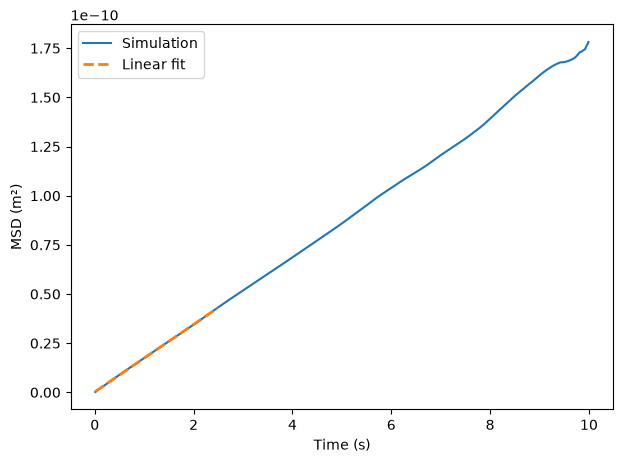

In [8]:
plt.figure(figsize=(7,5))

plt.plot(
    time,
    msd,
    label="Simulation",
)

fit_fraction = 0.25
n_fit = max(2, int(len(time) * fit_fraction))

plt.plot(
    time[:n_fit],
    slope * time[:n_fit] + intercept,
    "--",
    linewidth=2,
    label="Linear fit",
)

plt.xlabel("Time (s)")
plt.ylabel("MSD (m²)")

plt.legend()

plt.show()

In [9]:
print(f"Theoretical D : {D_theoretical:.3e}")

print(f"Estimated D   : {D_estimated:.3e}")

Theoretical D : 4.541e-12
Estimated D   : 4.282e-12
